# **Assignment 4**


## Preamble

- Loading Packages
- Generating Utilities

In [19]:
%matplotlib inline
import csv
import math
import matplotlib.pyplot as plt
import numpy as np
import scipy
import torch
import torch.nn as nn
import torch.nn.functional as F

from abc import ABC
from functools import partial
from itertools import product
from IPython.display import display, clear_output
from tqdm.notebook import tqdm
from typing import Optional, List, Tuple, Union, Dict

torch.manual_seed(1)
np.random.seed(1)

## Attention
Here you will implement a numpy version of the multihead attention layer.
A (single-head) attention function is defined as
\begin{align*}
    \text{Attention}(\tilde{\mathbf{Q}}, \tilde{\mathbf{K}}, \tilde{\mathbf{V}}) = \text{softmax}\left( \frac{\tilde{\mathbf{Q}} \tilde{\mathbf{K}}^\top}{\sqrt{k}} \right) \tilde{\mathbf{V}},
\end{align*}
where the queries $\tilde{\mathbf{Q}}$, keys $\tilde{\mathbf{K}}$, and values $\tilde{\mathbf{V}}$ are of dimension $k$.
Here, note in general that the number of keys and values should match while the number of queries can vary as the names suggest.
Intuitively, the inner product $\tilde{\mathbf{Q}} \tilde{\mathbf{K}}^\top$ finds the similarity between the queries and keys that is then weighted based on a softmax function.
Finally, we take the combination of the values weighted by the softmax output.
This particular attention is also known as a **softmax attention** since the weights are generated by a softmax---we can in fact replace this with other non-linearities, a common alternative is using a ReLU function.

A multihead attention function is defined as
\begin{align*}
    \text{Multihead}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \text{Concat}(\text{head}_1, \dots, \text{head}_B)W^O,
\end{align*}
where $\text{head}_b = \text{Attention}(\mathbf{Q} \mathbf{W}_{q, b}, \mathbf{K} \mathbf{W}_{k, b}, \mathbf{V} \mathbf{W}_{v, b})$ is the $b$'th attention head with query, key, and value weight matrices $\mathbf{W}_{q, b}, \mathbf{W}_{k, b}, \mathbf{W}_{v, b}$ respectively, and $\mathbf{W}_{o}$ is the output weight matrix.
Here, suppose that the model takes in a $d$-dimensional query, key, and value.
$\mathbf{W}_{q, b}$, $\mathbf{W}_{k, b}$, and $\mathbf{W}_{v, b}$ are $\mathbb{R}^{d \times k}$ weight matrices, and $\mathbf{W}_{o}$ is a $\mathbb{R}^{H k \times d}$ weight matrix, where $d$ is divisible by $k$.

In [20]:
def softmax(Z: np.ndarray) -> np.ndarray:
    """
    Numerically stable row-wise softmax.

    Args:
        Z (np.ndarray): The logits.
    """
    dist = None
    Z = Z - Z.max(axis=-1, keepdims=True)
    E = np.exp(Z)
    dist = E / E.sum(axis=-1, keepdims=True)
    return dist


class MultiHeadAttention:
    def __init__(self, embed_dim, num_heads, rng):
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads

        # For simplicity, all the dimensionalities are assumed to be the same
        self.W_q = rng.randn(embed_dim, embed_dim)
        self.W_k = rng.randn(embed_dim, embed_dim)
        self.W_v = rng.randn(embed_dim, embed_dim)
        self.W_o = rng.randn(embed_dim, embed_dim)

    def __call__(self, q, k, v):
        """
        The forward call of an attention layer.
        Args:
            q (np.ndarray): the query
            k (np.ndarray): the key
            v (np.ndarray): the value

        NOTE: For simplicity, we assume that all inputs have the same shape:
            (batch_size, context_length, embed_dim)

        NOTE: self.W_{q, k, v} of shape (embed_dim, embed_dim) can be interpreted as
             ________ ________ _______ ________
            |        |        |       |        |
            |        |        |       |        |
            |        |        |       |        |
            | head_1 | head_2 |  ...  | head_B |
            |        |        |       |        |
            |        |        |       |        |
            |________|________|_______|________|
            where head_h is shaped (embed_dim, embed_dim / B),
        """
        batch_size, context_length, embed_dim = q.shape

        # each attention head dimension
        head_dim = embed_dim // self.num_heads

        # the sqrt(d) scaling in attention head
        scale = 1.0 / math.sqrt(head_dim)
        out = None

        ### BEGIN SOLUTION
        # (B, T, E) B = batch size, T = context length, E = embedding dimension
        Q = q @ self.W_q
        K = k @ self.W_k
        V = v @ self.W_v

        # reshape into heads: (B, T, E) -> (B, H, T, D), H = # attention heads, D = dimension per head
        K = K.reshape(batch_size, context_length, self.num_heads, head_dim).transpose(0, 2, 1, 3)
        V = V.reshape(batch_size, context_length, self.num_heads, head_dim).transpose(0, 2, 1, 3)
        Q = Q.reshape(batch_size, context_length, self.num_heads, head_dim).transpose(0, 2, 1, 3)

        # Attention scores: (B, H, T, D) @ (B, H, D, T) -> (B, H, T, T)
        scores = (Q @ K.transpose(0, 1, 3, 2)) * scale 
        # Softmax over last axis (keys dim)
        attn = softmax(scores)
        # Weighted sum: (B, H, T, T) @ (B, H, T, D) -> (B, H, T, D)
        head_out = attn @ V

        # concat heads: (B, H, T, D) -> (B, T, H, D) -> (B, T, E)
        concat = head_out.transpose(0, 2, 1, 3).reshape(batch_size, context_length, embed_dim)
        out = concat @ self.W_o # Final W_o
        ### END SOLUTION

        # NOTE: out is shaped (batch_size, context_length, embed_dim)
        return out
    

print("== Testing multihead attention ==")
def test_mha():
    seed = 42
    rng = np.random.RandomState(seed)

    batch_size = 5
    context_length = 6
    embed_dim = 8
    num_heads = 4

    np_attention = MultiHeadAttention(embed_dim, num_heads, rng)
    torch_attention = nn.MultiheadAttention(
        embed_dim,
        num_heads,
        bias=False,
        batch_first=True,
    )

    # Use parameters from the NumPy attention model
    state_dict = {
        "in_proj_weight": torch.from_numpy(np.concatenate((
            np_attention.W_q.T,
            np_attention.W_k.T,
            np_attention.W_v.T,
        ), axis=0)).float(),
        "out_proj.weight": torch.from_numpy(
            np_attention.W_o.T
        ).float(),
    }
    torch_attention.load_state_dict(state_dict)

    # Sample random query, key, and value
    q = rng.randn(batch_size, context_length, embed_dim)
    k = rng.randn(batch_size, context_length, embed_dim)
    v = rng.randn(batch_size, context_length, embed_dim)

    np_out = np_attention(q, k, v)
    with torch.no_grad():
        (torch_out, _) = torch_attention(
            torch.from_numpy(q).float(),
            torch.from_numpy(k).float(),
            torch.from_numpy(v).float(),
            need_weights=False,
        )
    assert np.allclose(np_out, torch_out.numpy(), rtol=1e-5, atol=1e-5)

test_mha()

print("✅ All multihead attention tests passed")


== Testing multihead attention ==
✅ All multihead attention tests passed


## Sequence generation with next-token prediction
In this section we will start with training language models (LMs) using transformers and RNNs.
Since this is our first-time using PyTorch, we have already provided the code here.
Our task is to analyze the performance difference between a trained transformer LM and a trained RNN LM.

Following from the written component, recall that next-token prediction is based on factorizing the joint distribution $P(x_1, \dots, x_t) = \prod_{i=1}^{t} p(x_i | x_{<i})$.
The language model aims to maximize the likelihood
$$
\arg\max_\mathbf{W} \prod_{i=1}^{t} p(x_i | x_{<i}, \mathbf{W}).
$$
Here, $p(x_i | x_{<i}, \mathbf{W})$ is modelled using a transformer or an RNN.

To measure the performance of the trained model, one way is to evaluate its log likelihood on the heldout data
$$
\sum_{i=1}^t \log p(x^*_i | x^*_{<i}, \mathbf{W}),
$$
where $x^*_1, \dots, x^*_t$ is a heldout sequence.

Once we obtain a satisfactory model, we can autoregressively generate a sequence following the procedure:
1. At timestep $i$, compute the distribution $p(x_i | x_{< i}, \mathbf{W})$. Note that at $i = 1$ we assume $p(x_1 = \texttt{<BOS>}) = 1$.
2. Sample $\hat{x}_i \sim p( \cdot | x_{< i}, \mathbf{W})$
3. Repeat steps 1 and 2 until reaching $i = t$

In [21]:
class LanguageModel(nn.Module):
    def __init__(self, num_embed: int, embed_dim: int):
        super().__init__()
        self.num_embed = num_embed
        self.embed_dim = embed_dim
        self.embedding = nn.Embedding(num_embed, embed_dim)
        self.unembeding = nn.Linear(embed_dim, num_embed)

    def forward(self, xs: torch.tensor) -> Dict[str, torch.Tensor]:
        """
        Computes all of p(x_i | x_<i) given a sequence of tokens (x_1, ..., x_t).

        Args:
            xs (torch.Tensor): The batch of token sequences.
        """
        raise NotImplementedError(
            "This method should be implemented by subclasses to define the specific prediction."
        )
    
    def init_h(self, batch_size: int):
        """
        Initializes the cell state for the language model.

        Args:
            batch_size (int): The batch size for which to initialize the cell state.
        """
        raise NotImplementedError(
            "This method should be implemented by subclasses that require a cell state."
        )

    def step(self, x_i: torch.tensor, h_i: torch.tensor) -> Dict[str, torch.Tensor]:
        """
        Computes p(x_{i + 1} | x_<i+1).

        Args:
            x_i (torch.Tensor): The current token.
            h_i (torch.Tensor): The current hidden state/cache
        """
        raise NotImplementedError(
            "This method should be implemented by subclasses to define the specific prediction."
        )


class RNNLanguageModel(LanguageModel):
    def __init__(self, num_embed: int, embed_dim: int, hidden_dim: int):
        super().__init__(num_embed, embed_dim)
        self.hidden_dim = hidden_dim
        self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)

    def forward(self, xs: torch.tensor) -> Dict[str, torch.Tensor]:
        token_embed = self.embedding(xs)
        next_token_embed, _ = self.rnn(token_embed)
        next_token_unembed = self.unembeding(next_token_embed)
        return next_token_unembed

    def init_h(self, batch_size: int) -> torch.Tensor:
        return torch.zeros(1, batch_size, self.hidden_dim)
    
    def step(self, x_i: torch.Tensor, h_i: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        token_embed = self.embedding(x_i)
        next_token_embed, next_h = self.rnn(token_embed, h_i)
        next_token_unembed = self.unembeding(next_token_embed)
        return next_token_unembed, next_h


class TransformerLanguageModel(LanguageModel):
    def __init__(self, num_embed: int, embed_dim: int, num_heads: int):
        super().__init__(num_embed, embed_dim)
        self.num_heads = num_heads
        self.attention = nn.MultiheadAttention(embed_dim,
                                               num_heads,
                                               batch_first=True)

    def forward(self, xs: torch.Tensor) -> Dict[str, torch.Tensor]:
        token_embed = self.embedding(xs)
        mask = nn.Transformer.generate_square_subsequent_mask(
            sz=xs.shape[1],
            device=xs.device,
        )
        next_token_embed, _ = self.attention(token_embed,
                                             token_embed,
                                             token_embed,
                                             is_causal=True,
                                             attn_mask=mask)
        next_token_unembed = self.unembeding(next_token_embed)
        return next_token_unembed
    
    def init_h(self, batch_size: int) -> torch.Tensor:
        return torch.zeros(batch_size, 0, self.embed_dim)
    
    def step(self, x_i: torch.Tensor, h_i: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        token_embed = self.embedding(x_i)
        token_embed = torch.cat([h_i, token_embed], dim=1)
        mask = nn.Transformer.generate_square_subsequent_mask(
            sz=token_embed.shape[1],
            device=token_embed.device,
        )
        next_token_embed, att_out = self.attention(token_embed,
                                             token_embed,
                                             token_embed,
                                             is_causal=True,
                                             attn_mask=mask)
        next_token_unembed = self.unembeding(next_token_embed)
        return next_token_unembed[:, [-1]], token_embed

In [22]:
def ntp_update(model: LanguageModel, optimizer: torch.optim.Optimizer, xs: torch.Tensor):
    """
    Performs a model update through backpropagation on the next-token prediction objective.

    Args:
        model (LanguageModel): The language model to update.
        optimizer (torch.optim.Optimizer): The optimizer to perform gradient descent.
        xs (torch.Tensor): The batch of token sequences.
    """
    optimizer.zero_grad()
    logits = model(xs[:, :-1])
    bs, sl, vs = logits.shape
    loss = F.cross_entropy(
        logits.reshape(bs * sl, vs),
        xs[:, 1:].reshape(bs * sl),
        reduction="none",
    ).reshape(bs, sl)
    loss = torch.mean(torch.sum(loss, dim=1))
    loss.backward()
    optimizer.step()
    return loss, {}

### Log likelihood

In [23]:
def log_likelihood(lm: LanguageModel, xs: torch.Tensor):
    """
    Given a sequence x_1, ..., x_t, compute the likelihood f(x_1, ..., x_t | W).

    Args:
        model (LanguageModel): The language model to evaluate.
        xs (torch.Tensor): The batch of token sequences.
    """
    out = None
    ### BEGIN SOLUTION
    logits = lm(xs)
    log_probs = F.log_softmax(logits, dim=-1)

    # target next token
    targets = xs[:, 1:]

    # predictions for those targets in positions 0..sl-2
    log_probs = log_probs[:, :-1, :]

    # extract log p(x_t+1 | x<=t)
    token_log_probs = log_probs.gather(
        dim=-1,
        index=targets.unsqueeze(-1)
    ).squeeze(-1)

    # sum over time, average over batch
    out = token_log_probs.sum(dim=1).mean()
    ### END SOLUTION
    return out


print("== Testing log likelihood ==")

class MockLM():
    def __init__(self, vocab_size):
        self.vocab_size = vocab_size

    def __call__(self, xs: torch.Tensor):
        bs, sl = xs.shape
        return torch.cat((
            torch.eye(self.vocab_size + 1)[xs[:, 1]][:, None] * 1e8,
            torch.ones((bs, sl - 1, self.vocab_size + 1))
        ), dim=1)

def test_ll():
    seed = 42

    batch_size = 2
    vocab_size = 10
    seq_len = 4
    xs = torch.from_numpy(
        np.random.RandomState(seed).randint(0, vocab_size, (batch_size, seq_len))
    )
    mock_lm = MockLM(vocab_size)
    out = log_likelihood(mock_lm, xs)

    expected_out = torch.log(torch.tensor(1/(vocab_size + 1))) * (seq_len - 2)
    print(expected_out)
    assert np.allclose(out, expected_out)

test_ll()

print("✅ All log likelihood tests passed")


== Testing log likelihood ==
tensor(-4.7958)
✅ All log likelihood tests passed


### Autoregressive generation

In [24]:
def lm_generate(lm: LanguageModel, batch_size: int, seq_len: int, vocab_size: int):
    """
    Generate x_1, ..., x_t using f(. | W).

    Args:
        model (LanguageModel): The language model used to generate sequences.
        batch_size (int): The number of sequences to generate.
        seq_len (int): The length of each sequence.
        vocab_size (int): The number of words/tokens.
    """
    xs = []
    # Initialize x_1 = <BOS> for all samples.
    curr_x = torch.full((batch_size, 1), fill_value=vocab_size)
    ### BEGIN SOLUTION
    h = lm.init_h(batch_size) # Init hidden

    for _ in range(seq_len):
        # Get logits, pick next token
        logits, h = lm.step(curr_x, h)
        next_x = torch.argmax(logits, dim=-1)

        xs.append(next_x)
        curr_x = next_x
    ### END SOLUTION
    return torch.cat(xs, dim=-1)


print("== Testing lm generation ==")

class MockLM():
    def __init__(self, vocab_size, seq_len, batch_size):
        self.vocab_size = vocab_size
        self.seq_len = seq_len
        self.batch_size = batch_size
        self.h = torch.randint(0, self.vocab_size, (batch_size, self.seq_len))

    def init_h(self, batch_size: int):
        return torch.zeros(batch_size, dtype=int)

    def step(self, x_i: torch.Tensor, h_i: torch.Tensor):
        return torch.eye(self.vocab_size + 1)[
            torch.gather(self.h, dim=1, index=h_i[:, None])
        ] * 1e8, h_i + 1

def test_ll():
    batch_size = 2
    vocab_size = 10
    seq_len = 4
    mock_lm = MockLM(vocab_size, seq_len, batch_size)
    out = lm_generate(mock_lm, batch_size, seq_len - 1, vocab_size)

    expected_out = mock_lm.h[:, :-1]

    assert np.allclose(out, expected_out)

test_ll()

print("✅ All lm generation tests passed")


== Testing lm generation ==
✅ All lm generation tests passed


## Experiment on synthetic dataset

In [25]:
def increment_data_generator(batch_size: int, seq_len: int, vocab_size: int, seed=42):
    assert seq_len > 0
    assert vocab_size > 1
    assert vocab_size - seq_len > 0
    rng = np.random.RandomState(seed)
    while True:
        sequence = np.zeros((batch_size, seq_len + 1), dtype=int)
        sequence[:, 0] = vocab_size # <BOS>
        sequence[:, 1:] = rng.randint(vocab_size - seq_len, size=(batch_size, 1)) + np.arange(seq_len)[None]
        yield torch.from_numpy(sequence)

def compute_student_t_ci(n, err, axis=None):
    # alpha = 0.05
    mean_err = np.mean(err, axis=axis)
    std_err = np.std(err, axis=axis)
    ci = scipy.stats.t.ppf(0.975, df=n-1) * std_err / np.sqrt(n)
    return (mean_err - ci, mean_err + ci)

In [26]:
num_iters = 10000
val_interval = 100
batch_size = 32
lr = 1e-4

vocab_size = 10
num_heads = 2
hidden_dim = 10
embed_dim = 10
seq_len = 2
test_seq_len = 4

seed = 42

rnn_lm = RNNLanguageModel(vocab_size + 1, embed_dim, hidden_dim)
rnn_opt = torch.optim.Adam(
    rnn_lm.parameters(),
    lr=lr,
)

tf_lm = TransformerLanguageModel(vocab_size + 1, embed_dim, num_heads)
tf_opt = torch.optim.Adam(
    tf_lm.parameters(),
    lr=lr,
)

sequence_gen = increment_data_generator(batch_size, seq_len, vocab_size)
test_sequence_gen = increment_data_generator(batch_size, test_seq_len, vocab_size)

In [27]:
pbar = tqdm(range(num_iters))
tf_losses = []
rnn_losses = []

tf_ll = []
rnn_ll = []
for epoch_i in pbar:
    xs = next(sequence_gen)
    tf_loss, _ = ntp_update(tf_lm, tf_opt, xs)
    rnn_loss, _ = ntp_update(rnn_lm, rnn_opt, xs)
    tf_losses.append(tf_loss.detach().numpy())
    rnn_losses.append(rnn_loss.detach().numpy())
    pbar.set_description(f"Epoch {epoch_i}, NTP TF: {tf_loss.item():.4f} RNN {rnn_loss.item():.4f}")
    
    if (epoch_i + 1) % val_interval == 0 or epoch_i == 0:
        test_xs = next(test_sequence_gen)
        tf_ll.append(log_likelihood(tf_lm, test_xs).detach().numpy())
        rnn_ll.append(log_likelihood(rnn_lm, test_xs).detach().numpy())


  0%|          | 0/10000 [00:00<?, ?it/s]

ValueError: x and y must have same first dimension, but have shapes (101,) and (1,)

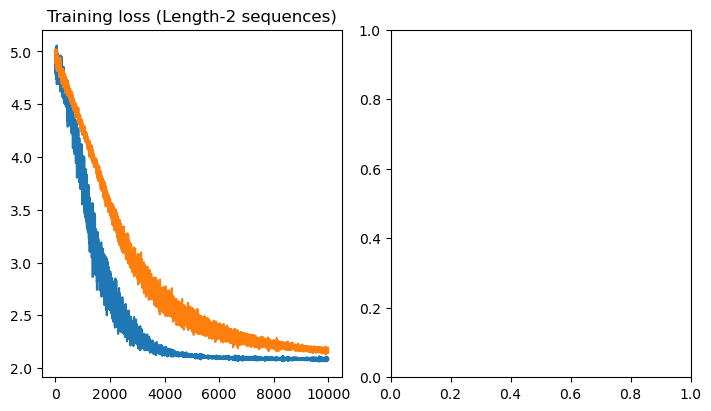

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(7, 4), layout="constrained")
axes[0].plot(tf_losses, label="Transformer")
axes[0].plot(rnn_losses, label="RNN")
axes[0].set_title("Training loss (Length-2 sequences)")

x_range = np.arange(len(tf_ll)) * val_interval

cis = compute_student_t_ci(batch_size, tf_ll, axis=-1)
axes[1].plot(x_range, np.mean(tf_ll, axis=-1))
axes[1].fill_between(
    x_range,
    cis[0],
    cis[1],
    alpha=0.3,
)

cis = compute_student_t_ci(batch_size, rnn_ll, axis=-1)
axes[1].plot(x_range, np.mean(rnn_ll, axis=-1))
axes[1].fill_between(
    x_range,
    cis[0],
    cis[1],
    alpha=0.3,
)

axes[1].set_title("Test log likelihood (Length-4 sequences)")

fig.supxlabel("Training iterations")

fig.legend(
    bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
    loc="lower center",
    ncols=5,
    borderaxespad=0.0,
    frameon=True,
    fontsize="8",
)

### Length generalization
Here we ask both the trained RNN and transformer to generate sequences of length 4, which are completely out of distribution as they are trained with sequences of length 2.
Knowing that the sequences of length 2 are incremental sequences, e.g., (1, 2), (2, 3), etc., it is natural to assume that the models will generate incremental sequences of length 4, e.g., (1, 2, 3, 4), (2, 3, 4, 5), etc., we call this length generalization.
Which model do you think achieves better length generalization?

In [ ]:
tf_out = lm_generate(tf_lm, 10, test_seq_len, vocab_size)
tf_out

In [ ]:
rnn_out = lm_generate(rnn_lm, 10, test_seq_len, vocab_size)
rnn_out

## Sequential ELBO
In this section we will train a sequential VAE that models a synthetic temporal dataset.
Recall that the sequential VAE is trained by optimizing the ELBO
$$
    \log p(\mathbf{x}_{1:t} | \mathbf{W}) \geq \sum_{i=1}^t \mathbb{E}_{\mathbf{h}_i \sim q_{\boldsymbol{\theta}}(\cdot | \mathbf{x}_{1:t})} \left[ \log p (\mathbf{x}_i | \mathbf{h}_i, \mathbf{W}) - D_\textrm{KL}(q_{\boldsymbol{\theta}}(\cdot | \mathbf{h}_{i - 1}, \mathbf{x}_{i}) || p(\cdot | \mathbf{h}_{i - 1}, \mathbf{W}_2)) \right],
$$
where $p(\mathbf{x}_i | \mathbf{h}_i, \mathbf{W}_1)$ is the decoder, $q_{\boldsymbol{\theta}}(\mathbf{h}_{i} | \mathbf{h}_{i - 1}, \mathbf{x}_{i})$ is the variational distribution, and $p(\mathbf{h}_i | \mathbf{h}_{i - 1}, \mathbf{W}_2)$ is the prior distribution at timestep $i$.
Since $\mathbf{x}_i$ is in pixel space, we will model the decoder $\log p (\mathbf{x}_i | \mathbf{h}_i, \mathbf{W})$ with the sigmoid transfer.

For simplicity, we assume that both the variational distribution and the prior distribution are Gaussian distributions:
$$
\begin{align*}
q_{\boldsymbol{\theta}}(\mathbf{h}_{i} | \mathbf{h}_{i - 1}, \mathbf{x}_{i}) &= \mathcal{N}(\mu_{\boldsymbol{\theta}} (\mathbf{h}_{i - 1}, \mathbf{x}_{i}), \sigma_{\boldsymbol{\theta}} (\mathbf{h}_{i - 1}, \mathbf{x}_{i})),\\
p(\mathbf{h}_{i} | \mathbf{h}_{i - 1} \mathbf{W}_2) &= \mathcal{N}(\mu_{\mathbf{W}_2} (\mathbf{h}_{i - 1}), \sigma_{\mathbf{W}_2} (\mathbf{h}_{i - 1})),
\end{align*}
$$
where $\mu_i$ and $\sigma_i$, where $i \in \{\boldsymbol{\theta}, \mathbf{W}_2 \}$ are the means and variances of the Gaussian.
There are two benefits of using Gaussians:
1. We can use the reparameterization trick to backpropagate through sampled random variables, and
2. We can compute the KL divergence between two Gaussians, $P$ and $Q$, analytically:
$$
D_\mathrm{KL}(P || Q) = \frac{1}{2} \left( \log \frac{\lvert \Sigma_Q \rvert}{\lvert \Sigma_P \rvert} - p + (\boldsymbol{\mu}_P - \boldsymbol{\mu}_Q)^\top \Sigma_Q^{-1} (\boldsymbol{\mu}_P - \boldsymbol{\mu}_Q) + \mathrm{trace}(\Sigma_Q^{-1} \Sigma_P) \right),
$$
where $p$ is the dimensionality of the random variable.

In this particular implementation, which we have already completed, $p$ and $q$ share parameters.
Specifically, they will be sharing the same RNN model to evolve the latent state.
Let $E$ be an encoder of observations, $f_\mathrm{fuse}$ be a function that maps an observation and a latent state to a latent state, $f_\mathbf{h}$ be the RNN model, $f_\mu$ be the function outputting the Gaussian means, and $f_\sigma$ be the function outputting the Gaussian variances.
Then, we can compute both the variational distribution and the prior distribution through
\begin{align*}
\mathbf{h}_q &= f_\mathrm{fuse}(\mathrm{concat}(E(\mathbf{x}_i), \mathbf{h}_i))\\
\mathbf{z}_q &= f_\mathbf{h}(\mathbf{h}_q)\\
\mu_{q}(\mathbf{h}_{i - 1}, \mathbf{x}_{i}) &= f_\mu(\mathbf{z}_q)\\
\sigma_{q}(\mathbf{h}_{i - 1}, \mathbf{x}_{i}) &= f_\sigma(\mathbf{z}_q)\\
\mathbf{z}_p &= f_\mathbf{h}(\mathbf{h}_i)\\
\end{align*}


### Reparameterization Trick

In [44]:
def gaussian_reparameterization(mean: torch.Tensor, var: torch.Tensor) -> torch.Tensor:
    """
    Applies the reparameterization trick to sample from a Gaussian distribution.

    Args:
        mean (torch.Tensor): The mean of the Gaussian distribution.
        var (torch.Tensor): The variance of the Gaussian distribution.
    """

    std = torch.sqrt(var)
    eps = torch.randn_like(std)
    out = mean + eps * std
    return out

### Variational autoencoder

In [45]:
class Encoder(nn.Module):
    def __init__(self, input_dim, latent_dim, hidden_dim):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim

        self.encoder = nn.ModuleList([
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        ])

    def encode(self, x_t: torch.Tensor) -> torch.Tensor:
        """
        Encodes an observation into the latent space, parameterized by a Gaussian.

        Args:
            x_t (torch.Tensor): The observation at timestep t.
        """
        out = x_t
        for layer in self.encoder:
            out = layer(out)
        return out

class Decoder(nn.Module):
    def __init__(self, input_dim, latent_dim, hidden_dim):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim

        self.decoder = nn.ModuleList([
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        ])

    def decode(self, h_t: torch.Tensor) -> torch.Tensor:
        """
        Decodes a latent state into an observation.

        Args:
            h_t (torch.Tensor): The latent state at timestep t.
        """
        out = h_t
        for layer in self.decoder:
            out = layer(out)
        return torch.sigmoid(out)
    

### State-space model

In [35]:
class StateSpaceModel(ABC, nn.Module):
    def __init__(self, latent_dim: int):
        super().__init__()
        self.h_0_mean = nn.Parameter(torch.zeros(latent_dim), requires_grad=False)
        self.h_0_var = nn.Parameter(torch.ones(latent_dim), requires_grad=False)
        self.fuser = nn.ModuleList([
            nn.Linear(2 * latent_dim, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, latent_dim),
        ])

    def init_h(self, batch_size: int) -> torch.Tensor:
        """
        Initializes the hidden state for the the latent dynamics.

        Args:
            batch_size (int): The batch size for which to initialize the hidden state.
        """
        mean = self.h_0_mean.unsqueeze(0).expand(batch_size, -1)
        var = torch.exp(self.h_0_var.unsqueeze(0).expand(batch_size, -1))
        h_curr = gaussian_reparameterization(mean, var)
        c_curr = self._init_c(batch_size)
        return {
            "mean": mean,
            "var": var,
            "h_curr": h_curr,
            "c_curr": c_curr,
        }
    
    def _init_c(self, batch_size: int) -> torch.Tensor:
        """
        Initializes the cell state for the the latent dynamics.

        Args:
            batch_size (int): The batch size for which to initialize the cell state.
        """
        raise NotImplementedError("This method should be implemented by subclasses that require a cell state.")

    def fuse(self, h_prev: torch.Tensor, h_curr: torch.Tensor) -> torch.Tensor:
        """
        Fuses the previous and current latent states to produce the next latent state.

        Args:
            h_prev (torch.Tensor): The previous latent state.
            h_curr (torch.Tensor): The current latent state.
        """
        out = torch.cat([h_prev, h_curr], dim=-1)
        for layer in self.fuser:
            out = layer(out)
        return out

    def forward(self, h_prev: torch.Tensor, c_prev: torch.Tensor) -> Dict[str, torch.Tensor]:
        """
        Computes the next latent state distribution given the previous latent state.

        Args:
            h_prev (torch.Tensor): The previous latent state.
            c_prev (Optional[torch.Tensor]): The previous cell state, if applicable.
        """
        raise NotImplementedError("This method should be implemented by subclasses to define the specific dynamics.")


class RNNSSM(StateSpaceModel):
    def __init__(self, latent_dim, hidden_dim):
        super().__init__(latent_dim)
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim

        self.rnn_cell = nn.GRUCell(latent_dim, hidden_dim)
        self.mean_layer = nn.Linear(hidden_dim, latent_dim)
        self.log_var_layer = nn.Linear(hidden_dim, latent_dim)

    def _init_c(self, batch_size: int) -> torch.Tensor:
        """
        Initializes the cell state for the RNN.

        Args:
            batch_size (int): The batch size for which to initialize the cell state.
        """
        return torch.zeros(batch_size, self.hidden_dim)

    def forward(self, h_prev: torch.Tensor, c_prev: torch.Tensor) -> Dict[str, torch.Tensor]:
        """
        Computes the next latent state distribution given the previous latent state.

        Args:
            h_prev (torch.Tensor): The previous latent state.
            c_prev (torch.Tensor): The previous cell state.
        """
        c_curr = self.rnn_cell(h_prev, c_prev)
        mean = self.mean_layer(c_curr)
        log_var = self.log_var_layer(c_curr)
        var = torch.exp(0.5 * log_var)
        h_curr = gaussian_reparameterization(mean, var)
        return {
            "mean": mean,
            "var": var,
            "h_curr": h_curr,
            "c_curr": c_curr,
        }

### Sequential ELBO objective
Here you will have to complete the components in order to compute the sequential ELBO objective.
We have already implemented the `unroll` function that computes the sequence of latent states given a sequence of observations.
It may be helpful to read its implementation for both the `prior` and `posterior` functions.

#### Unroll

In [36]:
def unroll(ssm: StateSpaceModel, encoded_xs: torch.Tensor) -> torch.Tensor:
    """
    Unrolls the state-space model to produce a sequence of latent states given a sequence of observations.

    Args:
        ssm (StateSpaceModel): The state-space model.
        encoded_xs (torch.Tensor): The sequence of encoded observations encoded_xs = [ex_1, ex_2, ..., ex_t],
                                   where ex_i is the encoded observation at time i.
    """

    batch_size, seq_len = encoded_xs.shape[:2]

    out_curr = ssm.init_h(batch_size)
    c_prev = out_curr["c_curr"]
    h_prev = out_curr["h_curr"]
    hs = [h_prev] # h_0
    for timestep_i in range(seq_len):
        h_curr = ssm.fuse(h_prev, encoded_xs[:, timestep_i])
        out_curr = ssm(h_curr, c_prev)

        hs.append(out_curr["h_curr"])
        c_prev = out_curr["c_curr"]
        h_prev = out_curr["h_curr"]
    return torch.stack(hs, dim=1)

print("== Testing unroll ==")

class MockSSM():
    def __init__(self, latent_dim, hidden_dim, seq_len, batch_size):
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.seq_len = seq_len + 1
        self.batch_size = batch_size
        self.h = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.c = torch.randn((batch_size, self.seq_len, self.hidden_dim))
        self.mean = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.var = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.fuse_called = False

    def expected_out(self):
        return self.h

    def init_h(self, batch_size: int):
        self.step = 1
        return {
            "c_curr": self.c[:, 0],
            "h_curr": self.h[:, 0],
        }

    def fuse(self, h_prev: torch.Tensor, h_curr: torch.tensor):
        self.fuse_called = True
        self.h_prev = h_prev
        return h_prev

    def __call__(self, h_i: torch.Tensor, c_i: torch.Tensor):
        assert torch.allclose(c_i, self.c[:, self.step - 1])
        assert torch.allclose(h_i, self.h_prev)
        out = {
            "c_curr": self.c[:, self.step],
            "h_curr": self.h[:, self.step],
            "mean": self.mean[:, self.step],
            "var": self.var[:, self.step],
        }
        self.step += 1
        return out

def test_unroll():
    batch_size = 2
    seq_len = 4
    latent_dim = 5
    hidden_dim = 1
    mock_ssm = MockSSM(latent_dim, hidden_dim, seq_len, batch_size)

    expected_out = mock_ssm.expected_out()
    
    xs = torch.randn((batch_size, seq_len))
    out = unroll(mock_ssm, xs)

    assert mock_ssm.fuse_called
    assert np.allclose(out, expected_out)

test_unroll()

print("✅ All unroll tests passed")


== Testing unroll ==
✅ All unroll tests passed


#### Prior

In [37]:
def prior(ssm: StateSpaceModel, hs: torch.Tensor) -> Dict[str, torch.Tensor]:
    """
    Computes the prior distribution over the latent states given the previous latent states.

    Args:
        ssm (StateSpaceModel): The latent state-space model.
        hs (torch.Tensor): The sequence of latent states hs = [h_0, h_1, h_2, ..., h_t],
                           where h_i is the latent state at time i.
    """

    batch_size, seq_len = hs.shape[:2]
    seq_len = seq_len - 1

    out_seq = {
        "mean": [],
        "var": [],
    }
    out_curr = ssm.init_h(batch_size)
    c_prev = out_curr["c_curr"]
    h_prev = out_curr["h_curr"]
    
    for timestep_i in range(seq_len):
        ### BEGIN SOLUTION
        out_curr = ssm(h_prev, c_prev)

        out_seq["mean"].append(out_curr["mean"])
        out_seq["var"].append(out_curr["var"])
        
        c_prev = out_curr["c_curr"]
        h_prev = out_curr["h_curr"]
        ### END SOLUTION

    return {k: torch.stack(v, dim=1) for k, v in out_seq.items()}


print("== Testing prior ==")

class MockSSM():
    def __init__(self, latent_dim, hidden_dim, seq_len, batch_size):
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.seq_len = seq_len + 1
        self.batch_size = batch_size
        self.h = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.c = torch.randn((batch_size, self.seq_len, self.hidden_dim))
        self.mean = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.var = torch.randn((batch_size, self.seq_len, self.latent_dim))

    def expected_out(self):
        return {
            "mean": self.mean[:, 1:],
            "var": self.var[:, 1:],
        }

    def init_h(self, batch_size: int):
        self.step = 1
        return {
            "c_curr": self.c[:, 0],
            "h_curr": self.h[:, 0],
        }

    def __call__(self, h_i: torch.Tensor, c_i: torch.Tensor):
        out = {
            "c_curr": self.c[:, self.step],
            "h_curr": self.h[:, self.step],
            "mean": self.mean[:, self.step],
            "var": self.var[:, self.step],
        }
        self.step += 1
        return out

def test_prior():
    batch_size = 2
    seq_len = 4
    latent_dim = 5
    hidden_dim = 1
    mock_ssm = MockSSM(latent_dim, hidden_dim, seq_len, batch_size)

    expected_out = mock_ssm.expected_out()
    
    hs = torch.randn((batch_size, seq_len + 1))
    out = prior(mock_ssm, hs)

    for k, v in expected_out.items():
        assert k in out
        assert np.allclose(out[k], v)

test_prior()

print("✅ All prior tests passed")


== Testing prior ==
✅ All prior tests passed


#### Posterior

In [38]:
def posterior(ssm: StateSpaceModel, hs: torch.Tensor, encoded_xs: torch.Tensor) -> Dict[str, torch.Tensor]:
    """
    Computes the posterior distribution over the current latent state given the previous latent state and the current observation.

    Args:
        ssm (StateSpaceModel): The state-space model.
        hs (torch.Tensor): The sequence of latent states hs = [h_0, h_1, h_2, ..., h_t], where h_i is the latent state at time i.
        encoded_xs (torch.Tensor): The sequence of encoded observations encoded_xs = [ex_1, ex_2, ..., ex_t],
                                   where ex_i is the encoded observation at time i.
    """

    batch_size, seq_len = encoded_xs.shape[:2]
    seq_len = seq_len

    out_seq = {
        "mean": [],
        "var": [],
    }
    out_curr = ssm.init_h(batch_size)
    c_prev = out_curr["c_curr"]
    h_prev = out_curr["h_curr"]
    for timestep_i in range(seq_len):
        ### BEGIN SOLUTION
        h_fused = ssm.fuse(h_prev, encoded_xs[:, timestep_i])
        out_curr = ssm(h_fused, c_prev)

        out_seq["mean"].append(out_curr["mean"])
        out_seq["var"].append(out_curr["var"])

        c_prev = out_curr["c_curr"]
        h_prev = out_curr["h_curr"]
        ### END SOLUTION
    return {k: torch.stack(v, dim=1) for k, v in out_seq.items()}


print("== Testing posterior ==")

class MockSSM():
    def __init__(self, latent_dim, hidden_dim, seq_len, batch_size):
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.seq_len = seq_len + 1
        self.batch_size = batch_size
        self.h = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.c = torch.randn((batch_size, self.seq_len, self.hidden_dim))
        self.mean = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.var = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.fuse_called = False

    def expected_out(self):
        return {
            "mean": self.mean[:, 1:],
            "var": self.var[:, 1:],
        }

    def init_h(self, batch_size: int):
        self.step = 1
        return {
            "c_curr": self.c[:, 0],
            "h_curr": self.h[:, 0],
        }

    def fuse(self, h_prev: torch.Tensor, h_curr: torch.tensor):
        self.fuse_called = True
        self.h_prev = h_prev
        return h_prev

    def __call__(self, h_i: torch.Tensor, c_i: torch.Tensor):
        assert torch.allclose(c_i, self.c[:, self.step - 1])
        assert torch.allclose(h_i, self.h_prev)
        out = {
            "c_curr": self.c[:, self.step],
            "h_curr": self.h[:, self.step],
            "mean": self.mean[:, self.step],
            "var": self.var[:, self.step],
        }
        self.step += 1
        return out

def test_posterior():
    batch_size = 2
    seq_len = 4
    latent_dim = 5
    hidden_dim = 1
    mock_ssm = MockSSM(latent_dim, hidden_dim, seq_len, batch_size)

    expected_out = mock_ssm.expected_out()
    
    hs = torch.randn((batch_size, seq_len + 1))
    xs = torch.randn((batch_size, seq_len))
    out = posterior(mock_ssm, hs, xs)

    assert mock_ssm.fuse_called
    for k, v in expected_out.items():
        assert k in out
        assert np.allclose(out[k], v)

test_posterior()

print("✅ All posterior tests passed")


== Testing posterior ==
✅ All posterior tests passed


#### Sequential ELBO

In [39]:
def sequential_elbo(x_recon: torch.Tensor,
                    x: torch.Tensor,
                    priors: Dict[str, torch.Tensor],
                    posteriors: Dict[str, torch.Tensor]) -> torch.Tensor:
    """
    Computes the ELBO for a single observation.

    Args:
        x_recon (torch.Tensor): The reconstructed observation.
        x (torch.Tensor): The original observation.
        priors (Dict[str, torch.Tensor]): The prior distribution over the latent states.
        posteriors (Dict[str, torch.Tensor]): The posterior distribution over the latent states.
    """
    latent_dim = priors["mean"].shape[2]

    mean_prior = priors["mean"]
    var_prior = priors["var"]
    mean_posterior = posteriors["mean"]
    var_posterior = posteriors["var"]
    elbo = None
    recon_loss = None
    kl_div = None

    # Compute the following:
    # 1. Reconstruction loss with binary cross-entropy loss per pixel
    # 2. KL divergence between the posterior and the prior
    # 3. Compute the ELBO using results from steps 1 & 2
    ### BEGIN SOLUTION
    recon_loss = F.binary_cross_entropy(x_recon, x, reduction="none")
    recon_loss = torch.sum(recon_loss, dim=(1, 2))
    kl_div = 0.5 * torch.sum(
        torch.sum((priors["mean"] - posteriors["mean"]) ** 2, dim=2),
        axis=1,
    )
    elbo = torch.mean(recon_loss + kl_div)
    ### END SOLUTION
    return elbo, {
        "recon_loss": recon_loss.mean().item(),
        "kl_div": kl_div.mean().item(),
        "mean_prior": mean_prior.mean(dim=0).detach(),
        "var_prior": var_prior.mean(dim=0).detach(),
        "mean_posterior": mean_posterior.mean(dim=0).detach(),
        "var_posterior": var_posterior.mean(dim=0).detach(),
    }


print("== Testing sequential ELBO ==")

def test_seq_elbo():
    batch_size = 2
    seq_len = 4
    obs_dim = 10
    latent_dim = 5

    xs = torch.rand((batch_size, seq_len, obs_dim))
    recon_xs = torch.rand((batch_size, seq_len, obs_dim))
    priors = {
        "mean": torch.randn((batch_size, seq_len, latent_dim)),
        "var": torch.ones((batch_size, seq_len, latent_dim)),
    }
    posteriors = {
        "mean": torch.randn((batch_size, seq_len, latent_dim)),
        "var": torch.ones((batch_size, seq_len, latent_dim)),
    }
    
    out, _ = sequential_elbo(recon_xs, xs, priors, posteriors)

    recon_loss = F.binary_cross_entropy(recon_xs, xs, reduction="none")
    recon_loss = torch.sum(recon_loss, dim=(1, 2))  # Sum over the feature dimension
    kl_div = 0.5 * torch.sum(
        torch.sum((priors["mean"] - posteriors["mean"]) ** 2, dim=2),
        axis=1,
    )
    expected_out = torch.mean(recon_loss + kl_div)

    assert np.allclose(out, expected_out)


test_seq_elbo()

print("✅ All sequential ELBO tests passed")


== Testing sequential ELBO ==
✅ All sequential ELBO tests passed


#### Update rule

In [40]:
def update_step(encoder: Encoder,
                decoder: Decoder,
                ssm: StateSpaceModel,
                optimizer: torch.optim.Optimizer,
                xs: torch.Tensor) -> torch.Tensor:
    """
    Performs a single update step of the VAE.

    Args:
        encoder (Encoder): The encoder module.
        decoder (Decoder): The decoder module.
        ssm (StateSpaceModel): The state-space model.
        optimizer (torch.optim.Optimizer): The optimizer for updating the model parameters.
        xs (torch.Tensor): The input observations.
    """

    elbo = None
    aux = None
    optimizer.zero_grad()
    # Complete the following:
    # 1. Encode the observation
    # 2. Unroll the state-space model to get the sequence of latent states
    # 3. Compute the prior and posterior distributions over the latent states
    # 4. Decode the latent states to get the reconstructed observation
    # 5. Compute the ELBO
    ### BEGIN SOLUTION
    encoded_xs = encoder.encode(xs) # Need to call this?
    hs = unroll(ssm, encoded_xs)

    pri = prior(ssm, hs)
    post = posterior(ssm, hs, encoded_xs)

    # sample from posterior
    zs = gaussian_reparameterization(post["mean"], post["var"])  # (bs, T, latent_dim)

    # Decode z_t -> x_hat_t
    bs, T, latent_dim = zs.shape
    zs_flat = zs.reshape(bs * T, latent_dim)
    x_hat = decoder.decode(zs_flat).reshape(bs, T, -1)

    # Reconstruction term
    recon = F.mse_loss(x_hat, xs, reduction="none").sum(dim=-1)
    # KL term
    q_mean, q_var, p_mean, p_var = post["mean"], post["var"], pri["mean"], pri["var"]
    kl = 0.5 * (
        torch.log(p_var) - torch.log(q_var)
        + (q_var + (q_mean - p_mean) ** 2) / p_var
        - 1
    ).sum(dim=-1)
    
    # ELBO = E[log p(x|z)] - KL (neg log-likelihood)
    elbo = -(recon + kl).mean()

    aux = {
        "recon": recon.mean().detach(),
        "kl": kl.mean().detach(),
    }
    ### END SOLUTION
    elbo.backward()
    optimizer.step()
    return elbo, aux

### Generating from sequential VAE

In [41]:
def generate_sequence(ssm: StateSpaceModel, decoder: Decoder, seq_len: int, batch_size: int) -> torch.Tensor:
    """
    Generates a sequence of observations from the state-space model.

    Args:
        ssm (StateSpaceModel): The state-space model.
        decoder (Decoder): The decoder module.
        seq_len (int): The length of the sequence to generate.
        batch_size (int): The batch size.
    """

    generated_sequence = None
    ### BEGIN SOLUTION
    sequence = []
    out = ssm.init_h(batch_size)
    h_prev = out["h_curr"]
    c_prev = out["c_curr"]

    for _ in range(seq_len):
        out = ssm(h_prev, c_prev)
        h_prev = out["h_curr"]
        c_prev = out["c_curr"]

        x_t = decoder.decode(h_prev)
        sequence.append(x_t)
        
    generated_sequence = torch.stack(sequence, dim=1)
    ### END SOLUTION
    return generated_sequence


print("== Testing generate sequence ==")

class MockSSM():
    def __init__(self, latent_dim, hidden_dim, seq_len, batch_size):
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.seq_len = seq_len + 1
        self.batch_size = batch_size
        self.h = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.c = torch.randn((batch_size, self.seq_len, self.hidden_dim))
        self.mean = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.var = torch.randn((batch_size, self.seq_len, self.latent_dim))
        self.fuse_called = False

    def expected_out(self):
        return self.h[:, 1:]

    def init_h(self, batch_size: int):
        self.step = 1
        return {
            "c_curr": self.c[:, 0],
            "h_curr": self.h[:, 0],
        }

    def __call__(self, h_i: torch.Tensor, c_i: torch.Tensor):
        assert torch.allclose(c_i, self.c[:, self.step - 1])
        out = {
            "c_curr": self.c[:, self.step],
            "h_curr": self.h[:, self.step],
            "mean": self.mean[:, self.step],
            "var": self.var[:, self.step],
        }
        self.step += 1
        return out
    

class MockDecoder():
    def __init__(self, obs_dim: int):
        self.obs_dim = obs_dim
        
    def decode(self, h_curr: torch.Tensor):
        bs, latent_dim = h_curr.shape
        obs = torch.zeros((bs, self.obs_dim))
        obs[:, :latent_dim] = h_curr
        return obs

def test_generate_sequence():
    batch_size = 2
    seq_len = 4
    latent_dim = 5
    hidden_dim = 1
    obs_dim = 10
    mock_ssm = MockSSM(latent_dim, hidden_dim, seq_len, batch_size)
    mock_decoder = MockDecoder(obs_dim)

    expected_out = torch.zeros((batch_size, seq_len, obs_dim))
    expected_out[..., :latent_dim] = mock_ssm.expected_out()
    
    out = generate_sequence(mock_ssm, mock_decoder, seq_len, batch_size)

    assert np.allclose(out, expected_out)

test_generate_sequence()

print("✅ All generate sequence tests passed")


== Testing generate sequence ==
✅ All generate sequence tests passed


## Experiment on sequential MNIST

In [30]:
def load_mnist(path: str) -> Tuple[np.ndarray, np.ndarray]:
    data = []
    reader = csv.reader(open(path, "r"), delimiter=",")
    for row in reader:
        data.append([
            float(col) for col in row
        ])
    data = np.asarray(data)
    X = data[:, :-1].astype(float) / 255.0
    y = data[:, -1:].astype(int)

    num_classes = np.unique(y).shape[0]
    class_idxes = dict()
    for class_i in range(num_classes):
        class_idxes[class_i] = np.where(y == class_i)[0]

    return X, y, class_idxes

def sequence_generator(path: str, batch_size: int, seed=42, p_flip=0.0):
    X, y, class_idxes = load_mnist(path)
    rng = np.random.RandomState(seed)
    seq_len = len(class_idxes) - 1
    while True:
        sequence = np.zeros((batch_size, seq_len, X.shape[1]))
        for timestep_i in range(seq_len):
            if timestep_i == seq_len - 1:
                last_class = rng.binomial(1, p_flip, size=batch_size)
                indices_1 = rng.choice(class_idxes[timestep_i], size=batch_size, replace=True)
                indices_2 = rng.choice(class_idxes[timestep_i + 1], size=batch_size, replace=True)
                sequence[:, timestep_i, :] = X[indices_1] * (1 - last_class[:, None]) + X[indices_2] * last_class[:, None]
            else:
                class_i = timestep_i
                indices = rng.choice(class_idxes[class_i], size=batch_size, replace=True)
                sequence[:, timestep_i, :] = X[indices]

        yield torch.from_numpy(sequence).float()

In [31]:
num_iters = 10000
log_interval = 2000
batch_size = 64
lr = 1e-3

large_latent_dim = 10
small_latent_dim = 2
cell_dim = 10
hidden_dim = 50
input_dim = 100
seq_len = 4

seed = 42

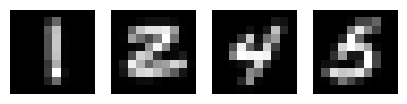

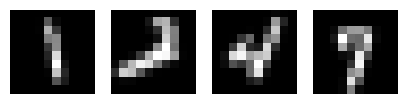

In [32]:
sequence_gen = sequence_generator("mnist_train.csv", batch_size, seed=seed, p_flip=0.5)

xs = next(sequence_gen)
for curr_x in xs[:2]:
    fig, axes = plt.subplots(1, seq_len, figsize=(5, 2))
    for i in range(seq_len):
        axes[i].imshow(curr_x[i].detach().numpy().reshape(10, 10), cmap="gray")
        axes[i].axis("off")
    plt.savefig("figure1.png")
    plt.show()

In [42]:
large_encoder = Encoder(input_dim, large_latent_dim, hidden_dim)
large_decoder = Decoder(input_dim, large_latent_dim, hidden_dim)
large_ssm = RNNSSM(large_latent_dim, cell_dim)
large_optimizer = torch.optim.Adam(
    list(large_encoder.parameters()) + list(large_decoder.parameters()) + list(large_ssm.parameters()),
    lr=lr,
)

small_encoder = Encoder(input_dim, small_latent_dim, hidden_dim)
small_decoder = Decoder(input_dim, small_latent_dim, hidden_dim)
small_ssm = RNNSSM(small_latent_dim, cell_dim)
small_optimizer = torch.optim.Adam(
    list(small_encoder.parameters()) + list(small_decoder.parameters()) + list(small_ssm.parameters()),
    lr=lr,
)

  0%|          | 0/10000 [00:00<?, ?it/s]

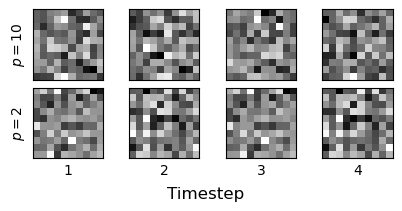

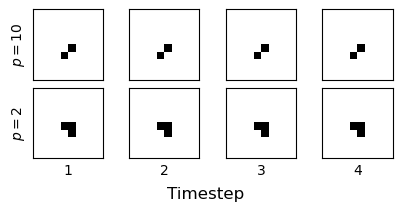

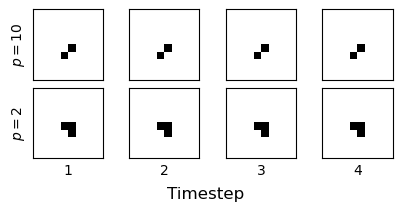

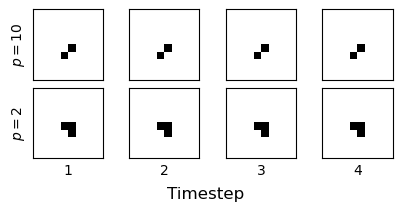

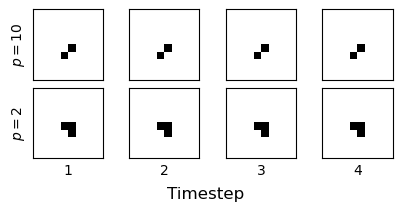

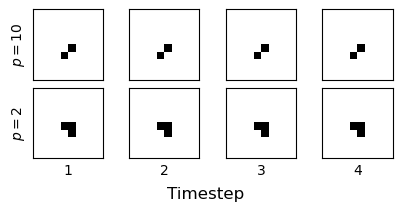

In [46]:
pbar = tqdm(range(num_iters))
for epoch_i in pbar:
    xs = next(sequence_gen)
    large_elbo, _ = update_step(large_encoder, large_decoder, large_ssm, large_optimizer, xs)
    small_elbo, _ = update_step(small_encoder, small_decoder, small_ssm, small_optimizer, xs)
    pbar.set_description(f"Epoch {epoch_i}, ELBO - Large: {large_elbo.item():.4f}, Small: {small_elbo.item():.4f}")
    if (epoch_i + 1) % log_interval == 0 or epoch_i == 0:
        fig, axes = plt.subplots(2, seq_len, figsize=(4, 2), layout="constrained")
        sequence_i = generate_sequence(large_ssm, large_decoder, seq_len=seq_len, batch_size=1)
        for i in range(seq_len):
            axes[0, i].imshow(sequence_i[0, i].detach().numpy().reshape(10, 10), cmap="gray")
            axes[0, i].set_xticks([])
            axes[0, i].set_yticks([])

        sequence_i = generate_sequence(small_ssm, small_decoder, seq_len=seq_len, batch_size=1)
        for i in range(seq_len):
            axes[1, i].imshow(sequence_i[0, i].detach().numpy().reshape(10, 10), cmap="gray")
            axes[1, i].set_xlabel(i + 1)
            axes[1, i].set_xticks([])
            axes[1, i].set_yticks([])

        axes[0, 0].set_ylabel("$p = 10$")
        axes[1, 0].set_ylabel("$p = 2$")
        fig.supxlabel("Timestep")
        plt.savefig("figure2.png")
        plt.show()


### Comparing $p = 2$ and $p = 10$
Here we vary the size of the latent dimension, with $p = 2$ and $p = 10$.
What can you say about the generated image quality between the two models?

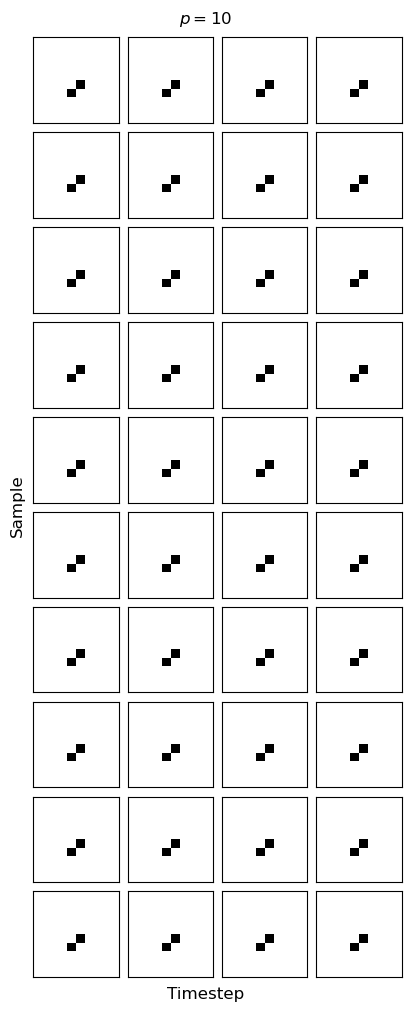

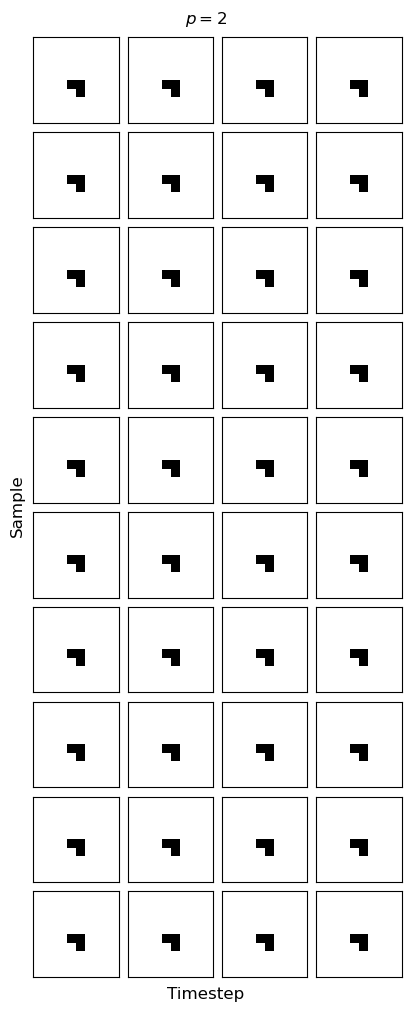

In [47]:
batch_size = 10
fig, axes = plt.subplots(batch_size, seq_len, figsize=(4, batch_size), layout="constrained")
sequences = generate_sequence(large_ssm, large_decoder, seq_len=seq_len, batch_size=batch_size)
for seq_i, seq in enumerate(sequences):
    for i in range(seq_len):
        axes[seq_i, i].imshow(seq[i].detach().numpy().reshape(10, 10), cmap="gray")
        axes[seq_i, i].set_xticks([])
        axes[seq_i, i].set_yticks([])

fig.suptitle("$p = 10$")
fig.supylabel("Sample")
fig.supxlabel("Timestep")
plt.savefig("figure3.png")
plt.show()

fig, axes = plt.subplots(batch_size, seq_len, figsize=(4, batch_size), layout="constrained")
sequences = generate_sequence(small_ssm, small_decoder, seq_len=seq_len, batch_size=batch_size)
for seq_i, seq in enumerate(sequences):
    for i in range(seq_len):
        axes[seq_i, i].imshow(seq[i].detach().numpy().reshape(10, 10), cmap="gray")
        axes[seq_i, i].set_xticks([])
        axes[seq_i, i].set_yticks([])

fig.suptitle("$p = 2$")
fig.supylabel("Sample")
fig.supxlabel("Timestep")
plt.savefig("figure4.png")
plt.show()

### Visualizing latent space
We can inspect the latent space by perturbing the latent states.
Here we will visualize the latent space for the $p = 2$ model.
We perturb the latent state $\mathbf{h}_t$ (here $t = 1$) by translating it---specifically we slide $\mathbf{h}_t$ for some distances $(x, y)$, covering a grid of space.
What can you conclude about the latent space as you sweep across it?

In [48]:
def generate_sequence_perturbed_2d(ssm: StateSpaceModel,
                                   decoder: Decoder,
                                   last_step: int,
                                   batch_size: int,
                                   h_min: float=-1.0,
                                   h_max: float=1.0) -> torch.Tensor:
    """
    Generate the observations by perturbing, in a grid, the latent state.
    NOTE: This only applies to 2D latent states.

    Args:
        ssm (StateSpaceModel): The state-space model.
        decoder (Decoder): The decoder module.
        last_step (int): The timestep t to generate.
        batch_size (int): The batch size.
        h_min (float): The minimum perturbed value.
        h_max (float): The maximum perturbed value.
    """
    delta = (h_max - h_min) / batch_size
    noise_vector = torch.cartesian_prod(
        torch.arange(h_min + delta, h_max + delta, delta),
        torch.arange(h_min + delta, h_max + delta, delta),
    )

    out_curr = ssm.init_h(1)
    c_prev = out_curr["c_curr"]
    h_prev = out_curr["h_curr"]

    for _ in range(last_step):
        out_curr = ssm(h_prev, c_prev)
        h_curr = out_curr["h_curr"]
        c_prev = out_curr["c_curr"]
        h_prev = h_curr

    x_recon = decoder.decode(h_curr + noise_vector)

    return x_recon

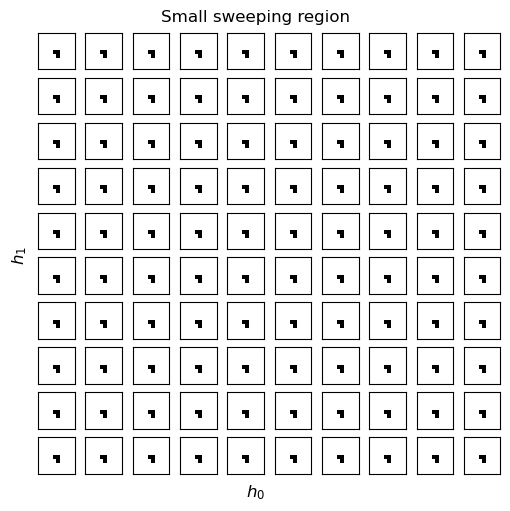

In [49]:
batch_size = 10
h_min = -1.0
h_max = 1.0
fig, axes = plt.subplots(batch_size, batch_size, figsize=(batch_size * 0.5, batch_size * 0.5), layout="constrained")
sequences = generate_sequence_perturbed_2d(small_ssm, small_decoder, last_step=1, batch_size=batch_size, h_min=h_min, h_max=h_max)
axes = axes.flatten()
for seq_i, seq in enumerate(sequences):
    axes[seq_i].imshow(seq.detach().numpy().reshape(10, 10), cmap="gray")
    axes[seq_i].set_xticks([])
    axes[seq_i].set_yticks([])

fig.suptitle("Small sweeping region")
fig.supylabel("$h_1$")
fig.supxlabel("$h_0$")
plt.savefig("figure5.png")
plt.show()

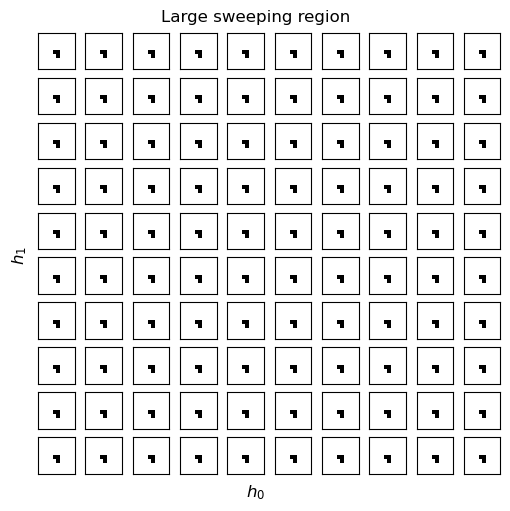

In [50]:
batch_size = 10
h_min = -5.0
h_max = 5.0
fig, axes = plt.subplots(batch_size, batch_size, figsize=(batch_size * 0.5, batch_size * 0.5), layout="constrained")
sequences = generate_sequence_perturbed_2d(small_ssm, small_decoder, last_step=1, batch_size=batch_size, h_min=h_min, h_max=h_max)
axes = axes.flatten()
for seq_i, seq in enumerate(sequences):
    axes[seq_i].imshow(seq.detach().numpy().reshape(10, 10), cmap="gray")
    axes[seq_i].set_xticks([])
    axes[seq_i].set_yticks([])

fig.suptitle("Large sweeping region")
fig.supylabel("$h_1$")
fig.supxlabel("$h_0$")
plt.savefig("figure6.png")
plt.show()